Mounted at /content/drive
Epoch 1, Training loss 1.3428,Validation loss 1.3889
Epoch 1000, Training loss 0.3320,Validation loss 0.3176
Epoch 2000, Training loss 0.3140,Validation loss 0.3056
Epoch 3000, Training loss 0.3034,Validation loss 0.3003
Epoch 4000, Training loss 0.2938,Validation loss 0.3003
Epoch 5000, Training loss 0.2843,Validation loss 0.3049
hidden_linear1.weight torch.Size([8, 11])
hidden_linear1.bias torch.Size([8])
hidden_linear2.weight torch.Size([8, 8])
hidden_linear2.bias torch.Size([8])
output_linear.weight torch.Size([1, 8])
output_linear.bias torch.Size([1])
MSE: 1060710514688.0
RMSE: $1029908.0127312342
R2: 0.6994711756706238


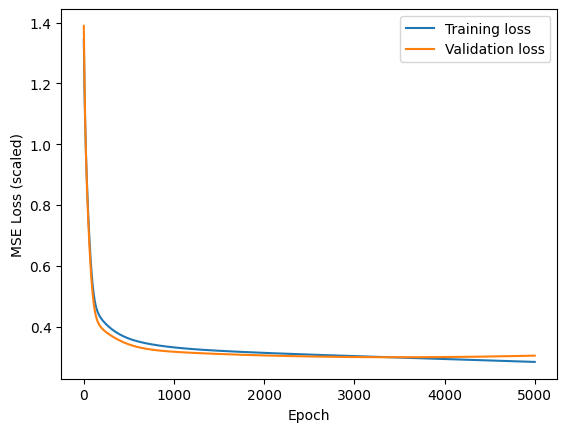

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
from google.colab import drive
import matplotlib.pyplot as plt
from sklearn import metrics
from collections import OrderedDict

drive.mount('/content/drive')
file_path = '/content/drive/MyDrive/Machine Learning/Housing.csv'
housing = pd.DataFrame(pd.read_csv(file_path))
housing = housing.drop(columns=['furnishingstatus'])

varlist =  ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']
def binary_map(x):
    return x.map({'yes': 1, 'no': 0})

housing[varlist] = housing[varlist].apply(binary_map)

from sklearn.model_selection import train_test_split
np.random.seed(0)
housing_training, housing_validation = train_test_split(housing, train_size = 0.8, test_size = 0.2, random_state = 100)

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
num_vars = ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']

housing_training[num_vars] = scaler.fit_transform(housing_training[num_vars])
housing_validation[num_vars] = scaler.transform(housing_validation[num_vars])

housing_training[["price"]] = scaler.fit_transform(housing_training[['price']])
housing_validation[["price"]] = scaler.transform(housing_validation[['price']])


X_train = torch.tensor(housing_training.drop(columns=['price']).values, dtype=torch.float32)
Y_train = torch.tensor(housing_training['price'].values, dtype=torch.float32).reshape(-1,1)
X_test = torch.tensor(housing_validation.drop(columns=['price']).values, dtype=torch.float32)
Y_test = torch.tensor(housing_validation['price'].values, dtype=torch.float32).reshape(-1,1)

seq_model = nn.Sequential(OrderedDict([('hidden_linear1', nn.Linear(11,8)),
                                       ('hidden_activation1', nn.Tanh()),
                                       ('hidden_linear2', nn.Linear(8,8)),
                                       ('hidden_activation2', nn.Tanh()),
                                       ('output_linear', nn.Linear(8,1))]))

optimizer = optim.SGD(seq_model.parameters(), lr=0.01)

def training_loop(n_epochs, optimizer, model, loss_fn, X_train, Y_train, X_test, Y_test):

  train_losses = []
  test_losses = []

  for epoch in range(1, n_epochs + 1):
    prediction = model(X_train)
    loss_train = loss_fn(prediction, Y_train)
    validation = model(X_test)
    loss_test = loss_fn(validation, Y_test)

    optimizer.zero_grad()
    loss_train.backward()
    optimizer.step()

    train_losses.append(loss_train.item())
    test_losses.append(loss_test.item())

    if epoch == 1 or epoch % 1000 == 0:
      print(f"Epoch {epoch}, Training loss {loss_train.item():.4f},"
            f"Validation loss {loss_test.item():.4f}")

  return train_losses, test_losses

train_losses, test_losses = training_loop(5000, optimizer, seq_model,
              nn.MSELoss(), X_train, Y_train, X_test, Y_test )

for name, param in seq_model.named_parameters():
    print(name, param.shape)

with torch.no_grad():
    Y_pred = seq_model(X_test)

Y_pred_real = scaler.inverse_transform(Y_pred.numpy())
Y_test_real = scaler.inverse_transform(Y_test.numpy())

print(f"MSE: {metrics.mean_squared_error(Y_test_real, Y_pred_real)}")
print(f"RMSE: ${np.sqrt(metrics.mean_squared_error(Y_test_real, Y_pred_real))}")
print(f"R2: {metrics.r2_score(Y_test_real, Y_pred_real)}")

plt.xlabel('Epoch')
plt.ylabel('MSE Loss (scaled)')
plt.plot(train_losses, label='Training loss')
plt.plot(test_losses, label='Validation loss')
plt.legend()
plt.show()
